## **Redes Neurais - Projeto 1: Regressão com MLP e Estudo de Ablação**
### Julia Souza Belmonte Lopes - RA: 168906

Este notebook contém o código do Projeto 1: uma MLP para uma tarefa de
regressão, um baseline treinado com SGD padrão (sem otimizadores adaptativos,
sem momentum, sem regularização) e um estudo de ablação comparando Momentum,
regularização L1, regularização L2 e Dropout, mantendo fixa a arquitetura do
baseline.

O relatório com a discussão crítica dos resultados está em um arquivo
separado (`relatorio.md`), conforme exigido no enunciado (o relatório não é
um caderno Jupyter).

## Reprodutibilidade

Foi utilizada uma semente fixa para tornar reprodutíveis a divisão dos
dados, a inicialização dos parâmetros da rede e as demais operações
pseudoaleatórias.

In [3]:
import random
from copy import deepcopy
from itertools import product

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 42

def definir_semente(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

definir_semente()
print(f"PyTorch:      {torch.__version__}")
print(f"Semente fixada em {SEED}.")

PyTorch:      2.14.0+cu130
Semente fixada em 42.


## Carregamento do dataset

O dataset original foi fornecido em PDF. Para manter o código simples e
robusto (sem depender de parsing de texto de PDF em tempo de execução),
os 300 pares `(x, y)` foram extraídos uma única vez e salvos em
`dados/dataset_projeto1.csv`, que é o arquivo efetivamente usado a partir
daqui.

In [5]:
dados = pd.read_csv("dados/dataset_projeto1.csv")

assert dados.shape == (300, 2)
assert list(dados.columns) == ["x", "y"]

print("Quantidade de amostras:", len(dados))
dados.head()

Quantidade de amostras: 300


             x         y
0     0.000000  0.798686
1     0.033445  0.644703
2     0.066890  1.057624
3     0.100334  1.503789
4     0.133779  0.893427
..         ...       ...
295   9.866221  0.449840
296   9.899666  1.180636
297   9.933110  1.034273
298   9.966555  1.320299
299  10.000000  1.320485

[300 rows x 2 columns]

## Verificação da integridade dos dados

Antes da divisão do dataset, verificamos dimensão, tipos, valores ausentes,
duplicidades e a organização da variável de entrada.

In [7]:
print("Dimensão do dataset:", dados.shape)
print("\nValores ausentes:\n", dados.isna().sum())
print("\nLinhas duplicadas:", dados.duplicated().sum())

# Checagem de valores não finitos (ex.: infinitos) coluna a coluna, convertendo
# explicitamente para array NumPy antes de aplicar isfinite. Chamar
# np.isfinite diretamente sobre o DataFrame inteiro depende de como a
# versão instalada de NumPy/pandas despacha esse ufunc, o que pode falhar
# com TypeError em alguns ambientes (ex.: certas combinações de versão no
# Windows/Anaconda) mesmo com dados puramente numéricos.
valores_nao_finitos = pd.Series({
    coluna: int((~np.isfinite(dados[coluna].to_numpy(dtype=float))).sum())
    for coluna in dados.columns
})
print("\nValores não finitos:\n", valores_nao_finitos)

print("\nx possui valores únicos?", dados["x"].is_unique)
print("x está em ordem crescente?", dados["x"].is_monotonic_increasing)

assert dados.isna().sum().sum() == 0
assert dados.duplicated().sum() == 0
assert valores_nao_finitos.sum() == 0

Dimensão do dataset: (300, 2)

Valores ausentes:
 x    0
y    0
dtype: int64

Linhas duplicadas: 0

Valores não finitos:
 x    0
y    0
dtype: int64

x possui valores únicos? True
x está em ordem crescente? True


In [8]:
resumo_estatistico = dados.describe().T
resumo_estatistico

   count      mean       std       min       25%       50%       75%        max
x  300.0  5.000000  2.901229  0.000000  2.500000  5.000000  7.500000  10.000000
y  300.0  0.465705  0.726711 -1.488851 -0.021091  0.452895  0.988865   2.655266

## Visualização inicial do dataset

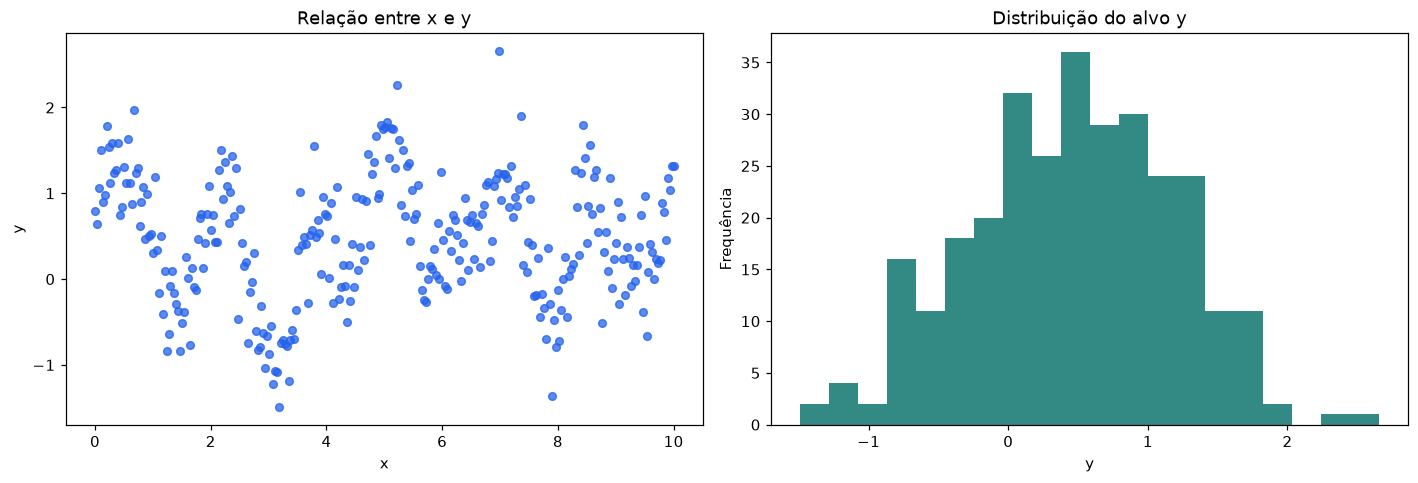

In [10]:
fig, eixos = plt.subplots(nrows=1, ncols=2, figsize=(13, 4.5))

eixos[0].scatter(dados["x"], dados["y"], s=25, alpha=0.75, color="#2563eb")
eixos[0].set_title("Relação entre x e y")
eixos[0].set_xlabel("x"); eixos[0].set_ylabel("y")

eixos[1].hist(dados["y"], bins=20, color="#0f766e", alpha=0.85)
eixos[1].set_title("Distribuição do alvo y")
eixos[1].set_xlabel("y"); eixos[1].set_ylabel("Frequência")

plt.tight_layout()
plt.show()

## Divisão em treino, validação e teste

O conjunto de dados é dividido em **10% treino / 10% validação / 80% teste**,
conforme especificado. Como há 300 amostras: 30 de treino, 30 de validação e
240 de teste. A divisão é aleatória (para não deixar cada partição isolada
numa região do domínio de `x`, já que os dados vêm ordenados) e reprodutível.

In [12]:
indices = np.arange(len(dados))

indices_desenvolvimento, indices_teste = train_test_split(
    indices, test_size=0.80, random_state=SEED, shuffle=True
)
indices_treino, indices_validacao = train_test_split(
    indices_desenvolvimento, test_size=0.50, random_state=SEED, shuffle=True
)

treino = dados.iloc[indices_treino].reset_index(drop=True)
validacao = dados.iloc[indices_validacao].reset_index(drop=True)
teste = dados.iloc[indices_teste].reset_index(drop=True)

assert len(treino) == 30 and len(validacao) == 30 and len(teste) == 240
assert set(indices_treino).isdisjoint(indices_validacao)
assert set(indices_treino).isdisjoint(indices_teste)
assert set(indices_validacao).isdisjoint(indices_teste)

print(f"Treino:    {len(treino):3d} amostras ({len(treino)/len(dados):.0%})")
print(f"Validação: {len(validacao):3d} amostras ({len(validacao)/len(dados):.0%})")
print(f"Teste:     {len(teste):3d} amostras ({len(teste)/len(dados):.0%})")
print("\nPartições verificadas: sem sobreposição, todas as amostras usadas.")

Treino:     30 amostras (10%)
Validação:  30 amostras (10%)
Teste:     240 amostras (80%)

Partições verificadas: sem sobreposição, todas as amostras usadas.


## Padronização dos dados

`x` e `y` são padronizados com `StandardScaler`. Para evitar vazamento de
dados, a média e o desvio-padrão são calculados **somente** com o conjunto
de treino (`fit_transform`); validação e teste usam apenas `transform`.

In [14]:
escalonador_x = StandardScaler()
escalonador_y = StandardScaler()

X_treino = escalonador_x.fit_transform(treino[["x"]]).astype(np.float32)
y_treino = escalonador_y.fit_transform(treino[["y"]]).astype(np.float32)
X_validacao = escalonador_x.transform(validacao[["x"]]).astype(np.float32)
y_validacao = escalonador_y.transform(validacao[["y"]]).astype(np.float32)
X_teste = escalonador_x.transform(teste[["x"]]).astype(np.float32)
y_teste = escalonador_y.transform(teste[["y"]]).astype(np.float32)

X_treino_tensor = torch.from_numpy(X_treino)
y_treino_tensor = torch.from_numpy(y_treino)
X_validacao_tensor = torch.from_numpy(X_validacao)
y_validacao_tensor = torch.from_numpy(y_validacao)
X_teste_tensor = torch.from_numpy(X_teste)
y_teste_tensor = torch.from_numpy(y_teste)

print("Parâmetros aprendidos somente no treino:")
print(f"x: média={escalonador_x.mean_[0]:.4f} | desvio={escalonador_x.scale_[0]:.4f}")
print(f"y: média={escalonador_y.mean_[0]:.4f} | desvio={escalonador_y.scale_[0]:.4f}")
print("\nVariância de y_validação padronizado (baseline trivial de comparação):",
      float(y_validacao.var()))

Parâmetros aprendidos somente no treino:
x: média=5.0613 | desvio=2.7595
y: média=0.3133 | desvio=0.7029

Variância de y_validação padronizado (baseline trivial de comparação): 1.149077296257019


## Construção da MLP

Classe única e reutilizável (usada no baseline **e** em todos os estudos de
ablação — `dropout=0.0` por padrão, ou seja, sem alterar a arquitetura entre
os experimentos).

In [16]:
class MLP(nn.Module):
    def __init__(self, neuronios_ocultos=(32, 16), ativacao="relu", dropout=0.0):
        super().__init__()
        ativacoes = {"relu": nn.ReLU, "tanh": nn.Tanh}
        if ativacao not in ativacoes:
            raise ValueError("A ativação deve ser 'relu' ou 'tanh'.")
        if not 0.0 <= dropout < 1.0:
            raise ValueError("O Dropout deve estar entre 0 e 1.")

        classe_ativacao = ativacoes[ativacao]
        camadas = []
        n_entradas = 1
        for n_neuronios in neuronios_ocultos:
            camadas.append(nn.Linear(n_entradas, n_neuronios))
            camadas.append(classe_ativacao())
            if dropout > 0:
                camadas.append(nn.Dropout(p=dropout))
            n_entradas = n_neuronios
        camadas.append(nn.Linear(n_entradas, 1))
        self.rede = nn.Sequential(*camadas)

    def forward(self, x):
        return self.rede(x)

definir_semente()
modelo_exemplo = MLP()
with torch.no_grad():
    saida_exemplo = modelo_exemplo(X_treino_tensor)
assert saida_exemplo.shape == y_treino_tensor.shape
print(modelo_exemplo)

MLP(
  (rede): Sequential(
    (0): Linear(in_features=1, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


## Função de treinamento (SGD)

Uma única função de treino cobre o baseline e todos os estudos de ablação:
`momentum`, `lambda_l1` e `lambda_l2` vêm com valor padrão `0.0`, ou seja, o
baseline (chamado sem esses argumentos) é sempre SGD padrão puro. O
otimizador usado é sempre `torch.optim.SGD` — em nenhum experimento é usado
Adam, RMSProp ou qualquer outro otimizador adaptativo, conforme exigido.

O critério de parada é *early stopping* monitorando o MSE de validação.

In [18]:
def criar_dataloader(tamanho_lote):
    gerador = torch.Generator()
    gerador.manual_seed(SEED)
    dataset_treino = TensorDataset(X_treino_tensor, y_treino_tensor)
    return DataLoader(dataset_treino, batch_size=tamanho_lote, shuffle=True, generator=gerador)


def treinar_modelo(
    modelo, taxa_aprendizado, tamanho_lote, numero_epocas=3000,
    patience=60, melhora_minima=1e-6, momentum=0.0, lambda_l1=0.0, lambda_l2=0.0,
):
    funcao_custo = nn.MSELoss()
    otimizador = torch.optim.SGD(
        modelo.parameters(), lr=taxa_aprendizado, momentum=momentum, weight_decay=lambda_l2
    )
    dataloader_treino = criar_dataloader(tamanho_lote)

    historico_treino, historico_validacao = [], []
    melhor_erro_validacao = float("inf")
    melhor_estado, melhor_epoca, epocas_sem_melhora = None, 0, 0

    for epoca in range(numero_epocas):
        modelo.train()
        erro_acumulado, quantidade_amostras = 0.0, 0

        for X_lote, y_lote in dataloader_treino:
            previsoes = modelo(X_lote)
            mse = funcao_custo(previsoes, y_lote)
            penalizacao_l1 = sum(p.abs().sum() for p in modelo.parameters())
            erro_total = mse + lambda_l1 * penalizacao_l1

            otimizador.zero_grad()
            erro_total.backward()
            otimizador.step()

            erro_acumulado += mse.item() * X_lote.shape[0]
            quantidade_amostras += X_lote.shape[0]

        erro_treino = erro_acumulado / quantidade_amostras

        modelo.eval()
        with torch.no_grad():
            erro_validacao = funcao_custo(modelo(X_validacao_tensor), y_validacao_tensor).item()

        historico_treino.append(erro_treino)
        historico_validacao.append(erro_validacao)

        if erro_validacao < melhor_erro_validacao - melhora_minima:
            melhor_erro_validacao = erro_validacao
            melhor_estado = deepcopy(modelo.state_dict())
            melhor_epoca = epoca + 1
            epocas_sem_melhora = 0
        else:
            epocas_sem_melhora += 1

        if epocas_sem_melhora >= patience:
            break

    modelo.load_state_dict(melhor_estado)
    return {
        "modelo": modelo,
        "historico_treino": historico_treino,
        "historico_validacao": historico_validacao,
        "melhor_erro_validacao": melhor_erro_validacao,
        "melhor_epoca": melhor_epoca,
        "epocas_executadas": len(historico_treino),
    }

print("Função de treinamento definida.")

Função de treinamento definida.


## Busca empírica do baseline

**Observação sobre uma tentativa anterior:** uma primeira busca (arquiteturas
pequenas, `taxa_aprendizado ∈ {0.001, 0.01}`, `patience=20`) resultou em um
"baseline" cujo MSE de validação (~1.16, padronizado) ficava **acima** da
variância trivial de `y_validação` (~1.15) — ou seja, o modelo não aprendia
nada além da média. Ao investigar, isolamos a causa: com SGD sem momentum e
taxas de aprendizado tão baixas, o modelo mal começa a se mover para longe da
inicialização quando `patience=20` já interrompe o treino (a validação piora
por poucas épocas de ruído antes de qualquer convergência real).

A correção **não troca o otimizador** (continua sendo SGD padrão, sem
momentum, sem Adam/RMSProp) — apenas amplia a faixa de `taxa_aprendizado`
pesquisada e aumenta o `patience`, exatamente os hiperparâmetros que o
enunciado pede para variar na busca empírica.

In [20]:
arquiteturas = [(16,), (32,), (32, 16), (64, 32)]
ativacoes = ["relu", "tanh"]
taxas_aprendizado = [0.01, 0.05, 0.1, 0.3, 0.5]
tamanhos_lote = [8, 16, 30]

configuracoes = list(product(arquiteturas, ativacoes, taxas_aprendizado, tamanhos_lote))
print("Quantidade de configurações avaliadas:", len(configuracoes))

PATIENCE_BUSCA = 60
EPOCAS_BUSCA = 3000

resultados_busca = []
for arquitetura, ativacao, taxa_aprendizado, tamanho_lote in configuracoes:
    definir_semente()
    modelo_candidato = MLP(neuronios_ocultos=arquitetura, ativacao=ativacao)
    resultado_candidato = treinar_modelo(
        modelo_candidato, taxa_aprendizado=taxa_aprendizado, tamanho_lote=tamanho_lote,
        numero_epocas=EPOCAS_BUSCA, patience=PATIENCE_BUSCA,
    )
    resultados_busca.append({
        "arquitetura": arquitetura, "ativacao": ativacao,
        "taxa_aprendizado": taxa_aprendizado, "tamanho_lote": tamanho_lote,
        "mse_validacao": resultado_candidato["melhor_erro_validacao"],
        "melhor_epoca": resultado_candidato["melhor_epoca"],
        "epocas_executadas": resultado_candidato["epocas_executadas"],
    })

tabela_busca = pd.DataFrame(resultados_busca).sort_values(
    "mse_validacao", ascending=True
).reset_index(drop=True)
tabela_busca.head(10)

Quantidade de configurações avaliadas: 120


    arquitetura ativacao  ...  melhor_epoca  epocas_executadas
0      (32, 16)     relu  ...           149                209
1      (32, 16)     relu  ...           123                183
2         (16,)     tanh  ...           185                245
3         (32,)     tanh  ...           185                245
4      (32, 16)     tanh  ...            85                145
..          ...      ...  ...           ...                ...
115    (32, 16)     tanh  ...             1                 61
116       (16,)     tanh  ...             1                 61
117    (64, 32)     tanh  ...             1                 61
118       (32,)     tanh  ...             1                 61
119       (32,)     relu  ...             1                 61

[120 rows x 7 columns]

## Seleção do baseline

A configuração com o menor MSE de validação é escolhida como baseline. A
arquitetura, ativação, taxa de aprendizado e tamanho de lote selecionados
aqui são **mantidos fixos** em todos os estudos de ablação a seguir.

In [22]:
melhor_configuracao = tabela_busca.iloc[0]
arquitetura_baseline = melhor_configuracao["arquitetura"]
ativacao_baseline = melhor_configuracao["ativacao"]
taxa_baseline = float(melhor_configuracao["taxa_aprendizado"])
lote_baseline = int(melhor_configuracao["tamanho_lote"])

print("Configuração escolhida para o baseline:")
print("Arquitetura:", arquitetura_baseline)
print("Ativação:", ativacao_baseline)
print("Taxa de aprendizado:", taxa_baseline)
print("Tamanho do lote:", lote_baseline)
print("MSE de validação na busca:", f"{melhor_configuracao['mse_validacao']:.6f}")

PATIENCE = 60
EPOCAS = 3000

definir_semente()
modelo_baseline = MLP(neuronios_ocultos=arquitetura_baseline, ativacao=ativacao_baseline)
resultado_baseline = treinar_modelo(
    modelo_baseline, taxa_aprendizado=taxa_baseline, tamanho_lote=lote_baseline,
    numero_epocas=EPOCAS, patience=PATIENCE,
)
modelo_baseline = resultado_baseline["modelo"]

print("\nÉpocas executadas:", resultado_baseline["epocas_executadas"])
print("Melhor época:", resultado_baseline["melhor_epoca"])
print("Melhor MSE de validação:", f"{resultado_baseline['melhor_erro_validacao']:.6f}")

resultados_modelos = {"Baseline": resultado_baseline}

Configuração escolhida para o baseline:
Arquitetura: (32, 16)
Ativação: relu
Taxa de aprendizado: 0.3
Tamanho do lote: 16
MSE de validação na busca: 0.888551

Épocas executadas: 209
Melhor época: 149
Melhor MSE de validação: 0.888551


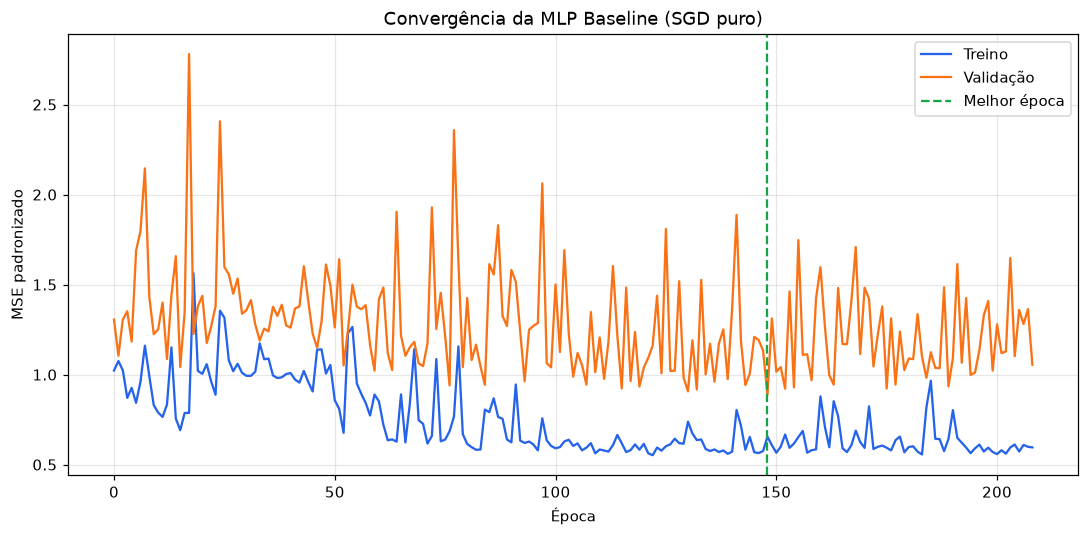

In [23]:
plt.figure(figsize=(10, 5))
plt.plot(resultado_baseline["historico_treino"], label="Treino", color="#2563eb")
plt.plot(resultado_baseline["historico_validacao"], label="Validação", color="#f97316")
plt.axvline(resultado_baseline["melhor_epoca"] - 1, color="#16a34a", linestyle="--", label="Melhor época")
plt.xlabel("Época"); plt.ylabel("MSE padronizado")
plt.title("Convergência da MLP Baseline (SGD puro)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("figuras/fig1_baseline_convergencia.png", dpi=130)
plt.show()

## Estudo de ablação

Para cada técnica, mantemos arquitetura, ativação, taxa de aprendizado e
tamanho de lote idênticos ao baseline — muda apenas o componente estudado.

In [25]:
def treinar_variante(nome, **kwargs):
    definir_semente()
    modelo = MLP(
        neuronios_ocultos=arquitetura_baseline,
        ativacao=ativacao_baseline,
        dropout=kwargs.pop("dropout", 0.0),
    )
    resultado = treinar_modelo(
        modelo, taxa_aprendizado=taxa_baseline, tamanho_lote=lote_baseline,
        numero_epocas=EPOCAS, patience=PATIENCE, **kwargs,
    )
    resultados_modelos[nome] = resultado
    print(f"{nome:10s} | melhor_epoca={resultado['melhor_epoca']:4d} | "
          f"épocas={resultado['epocas_executadas']:4d} | "
          f"MSE_val={resultado['melhor_erro_validacao']:.6f}")
    return resultado

_ = treinar_variante("Momentum", momentum=0.9)
_ = treinar_variante("L1", lambda_l1=1e-4)
_ = treinar_variante("L2", lambda_l2=1e-4)
_ = treinar_variante("Dropout", dropout=0.2)

Momentum   | melhor_epoca=  81 | épocas= 141 | MSE_val=1.149095
L1         | melhor_epoca= 116 | épocas= 176 | MSE_val=0.860780
L2         | melhor_epoca= 149 | épocas= 209 | MSE_val=0.895273
Dropout    | melhor_epoca= 185 | épocas= 245 | MSE_val=0.884123


### Modelo combinado

Combina as **duas técnicas individuais que mais reduziram o MSE de
validação** frente ao baseline (decidido a posteriori, a partir dos
resultados acima — não escolhido a priori).

In [27]:
ranking_individual = pd.DataFrame([
    {"Modelo": nome, "mse_validacao": r["melhor_erro_validacao"]}
    for nome, r in resultados_modelos.items()
]).sort_values("mse_validacao")
print(ranking_individual.to_string(index=False))

candidatas = ranking_individual[ranking_individual["Modelo"] != "Baseline"]
melhores_duas = candidatas.nsmallest(2, "mse_validacao")["Modelo"].tolist()
print("\nDuas melhores técnicas individuais:", melhores_duas)

combo_kwargs, combo_dropout = {}, 0.0
for tecnica in melhores_duas:
    if tecnica == "Momentum":
        combo_kwargs["momentum"] = 0.9
    elif tecnica == "L1":
        combo_kwargs["lambda_l1"] = 1e-4
    elif tecnica == "L2":
        combo_kwargs["lambda_l2"] = 1e-4
    elif tecnica == "Dropout":
        combo_dropout = 0.2

_ = treinar_variante("Combinado", dropout=combo_dropout, **combo_kwargs)
print("\nComponentes do combinado:", melhores_duas)

  Modelo  mse_validacao
      L1       0.860780
 Dropout       0.884123
Baseline       0.888551
      L2       0.895273
Momentum       1.149095

Duas melhores técnicas individuais: ['L1', 'Dropout']
Combinado  | melhor_epoca= 116 | épocas= 176 | MSE_val=0.896461

Componentes do combinado: ['L1', 'Dropout']


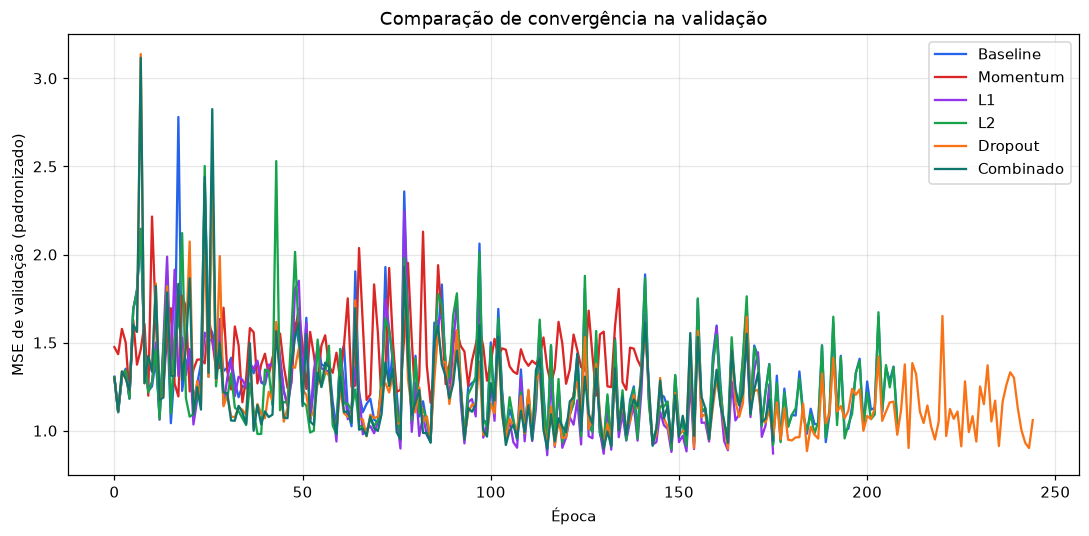

In [28]:
plt.figure(figsize=(10, 5))
cores = {"Baseline": "#2563eb", "Momentum": "#dc2626", "L1": "#9333ea",
         "L2": "#16a34a", "Dropout": "#f97316", "Combinado": "#0f766e"}
for nome, resultado in resultados_modelos.items():
    plt.plot(resultado["historico_validacao"], label=nome, color=cores.get(nome))
plt.xlabel("Época"); plt.ylabel("MSE de validação (padronizado)")
plt.title("Comparação de convergência na validação")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("figuras/fig2_comparacao_validacao.png", dpi=130)
plt.show()

## Comparação na validação

In [30]:
tabela_validacao = pd.DataFrame([
    {
        "Modelo": nome,
        "Melhor época": r["melhor_epoca"],
        "Épocas executadas": r["epocas_executadas"],
        "MSE de validação": r["melhor_erro_validacao"],
    }
    for nome, r in resultados_modelos.items()
]).sort_values("MSE de validação").reset_index(drop=True)
tabela_validacao

      Modelo  Melhor época  Épocas executadas  MSE de validação
0         L1           116                176          0.860780
1    Dropout           185                245          0.884123
2   Baseline           149                209          0.888551
3         L2           149                209          0.895273
4  Combinado           116                176          0.896461
5   Momentum            81                141          1.149095

## Avaliação final no conjunto de teste

As previsões são revertidas para a escala original de `y` antes do cálculo
das métricas (MAE, MSE, RMSE, R²). O conjunto de teste não participou de
nenhuma decisão anterior (nem arquitetura, nem hiperparâmetros).

In [32]:
def avaliar_no_teste(modelo):
    modelo.eval()
    with torch.no_grad():
        previsoes_padronizadas = modelo(X_teste_tensor).cpu().numpy()
    previsoes = escalonador_y.inverse_transform(previsoes_padronizadas).ravel()
    reais = escalonador_y.inverse_transform(y_teste).ravel()
    mse = mean_squared_error(reais, previsoes)
    return {
        "MSE": mse, "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(reais, previsoes),
        "R2": r2_score(reais, previsoes),
        "valores_reais": reais, "previsoes": previsoes,
    }

resultados_teste = {nome: avaliar_no_teste(r["modelo"]) for nome, r in resultados_modelos.items()}

tabela_teste = pd.DataFrame([
    {"Modelo": nome, "MSE": m["MSE"], "RMSE": m["RMSE"], "MAE": m["MAE"], "R2": m["R2"]}
    for nome, m in resultados_teste.items()
]).sort_values("RMSE").reset_index(drop=True)
tabela_teste

      Modelo       MSE      RMSE       MAE        R2
0         L1  0.445138  0.667187  0.549974  0.139154
1  Combinado  0.449823  0.670689  0.553556  0.130094
2   Baseline  0.462627  0.680167  0.562282  0.105333
3    Dropout  0.468017  0.684118  0.560014  0.094910
4         L2  0.468539  0.684499  0.564988  0.093901
5   Momentum  0.559934  0.748287  0.602769 -0.082847

In [33]:
tabela_final = pd.merge(
    tabela_validacao[["Modelo", "MSE de validação"]], tabela_teste, on="Modelo"
).sort_values("RMSE").reset_index(drop=True)
tabela_final.to_csv("tabela_final.csv", index=False)
tabela_final

      Modelo  MSE de validação       MSE      RMSE       MAE        R2
0         L1          0.860780  0.445138  0.667187  0.549974  0.139154
1  Combinado          0.896461  0.449823  0.670689  0.553556  0.130094
2   Baseline          0.888551  0.462627  0.680167  0.562282  0.105333
3    Dropout          0.884123  0.468017  0.684118  0.560014  0.094910
4         L2          0.895273  0.468539  0.684499  0.564988  0.093901
5   Momentum          1.149095  0.559934  0.748287  0.602769 -0.082847

## Curvas estimadas, parity plot e resíduos

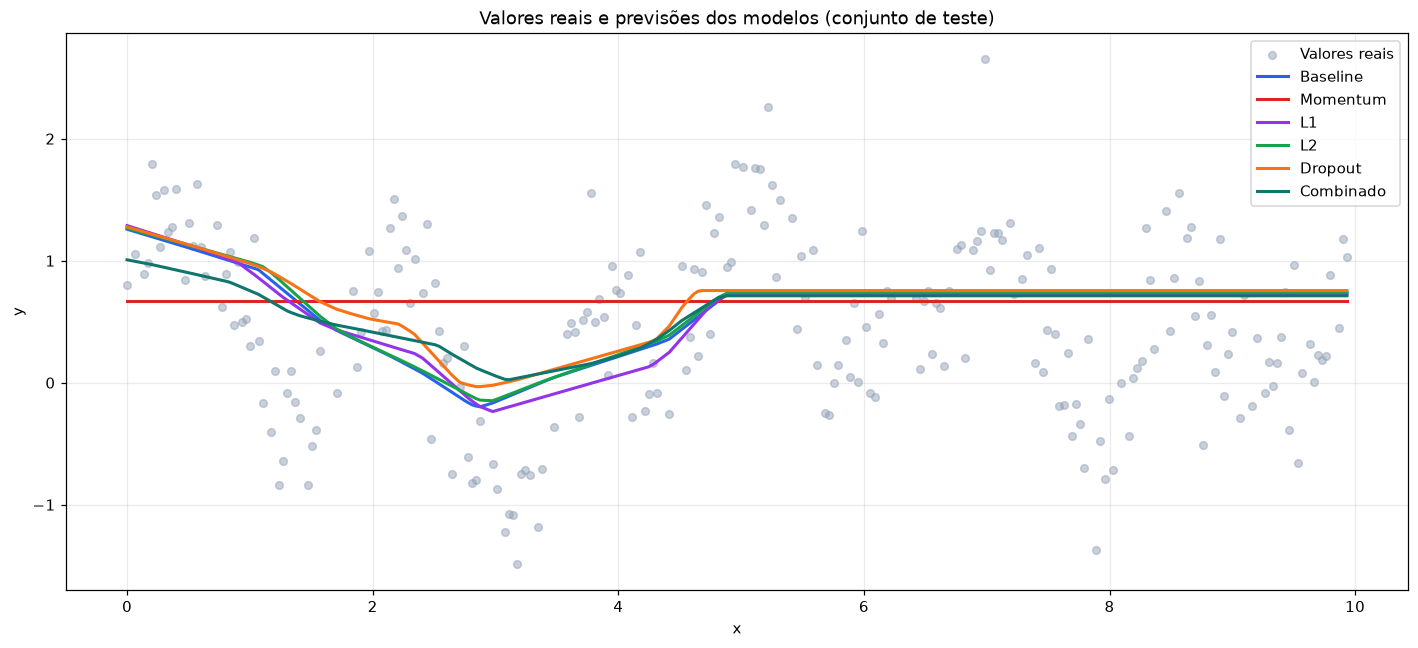

In [35]:
x_teste_original = teste["x"].to_numpy()
ordem = np.argsort(x_teste_original)
y_teste_original = resultados_teste["Baseline"]["valores_reais"]

plt.figure(figsize=(13, 6))
plt.scatter(x_teste_original, y_teste_original, color="#94a3b8", alpha=0.5, s=25, label="Valores reais")
cores_modelos = {"Baseline": "#2563eb", "Momentum": "#dc2626", "L1": "#9333ea",
                 "L2": "#16a34a", "Dropout": "#f97316", "Combinado": "#0f766e"}
for nome, metricas in resultados_teste.items():
    plt.plot(x_teste_original[ordem], metricas["previsoes"][ordem],
              color=cores_modelos[nome], linewidth=2, label=nome)
plt.xlabel("x"); plt.ylabel("y")
plt.title("Valores reais e previsões dos modelos (conjunto de teste)")
plt.legend(); plt.grid(alpha=0.25); plt.tight_layout()
plt.savefig("figuras/fig_curvas_previsao.png", dpi=130)
plt.show()

Melhor modelo no teste (menor RMSE): L1


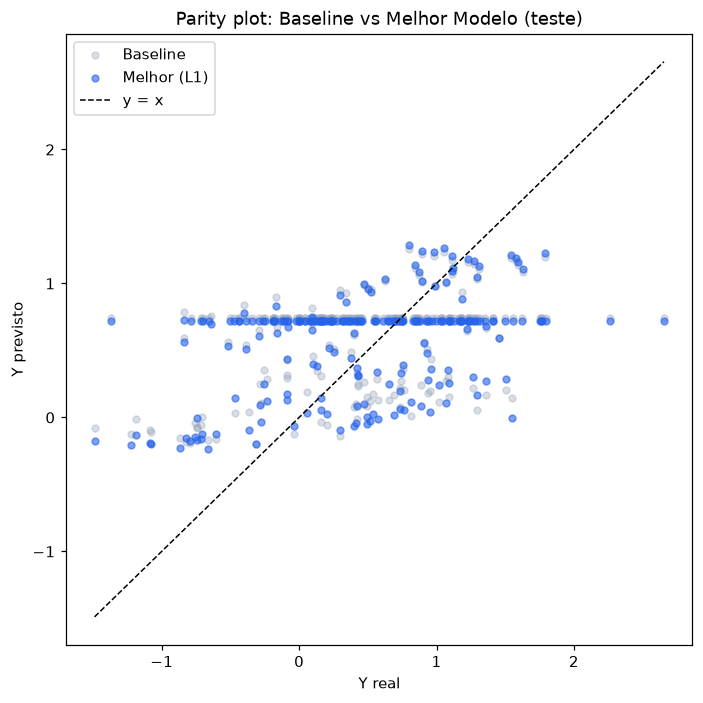

In [36]:
melhor_modelo_teste = tabela_teste.iloc[0]["Modelo"]
r_melhor = resultados_teste[melhor_modelo_teste]
r_baseline_teste = resultados_teste["Baseline"]

plt.figure(figsize=(6.5, 6.5))
lims = [min(r_melhor["valores_reais"].min(), r_melhor["previsoes"].min()),
        max(r_melhor["valores_reais"].max(), r_melhor["previsoes"].max())]
plt.scatter(r_baseline_teste["valores_reais"], r_baseline_teste["previsoes"],
            alpha=0.35, s=20, label="Baseline", color="#94a3b8")
plt.scatter(r_melhor["valores_reais"], r_melhor["previsoes"],
            alpha=0.6, s=20, label=f"Melhor ({melhor_modelo_teste})", color="#2563eb")
plt.plot(lims, lims, "k--", linewidth=1, label="y = x")
plt.xlabel("Y real"); plt.ylabel("Y previsto")
plt.title("Parity plot: Baseline vs Melhor Modelo (teste)")
plt.legend(); plt.tight_layout()
plt.savefig("figuras/fig3_parity_plot.png", dpi=130)
plt.show()

print("Melhor modelo no teste (menor RMSE):", melhor_modelo_teste)

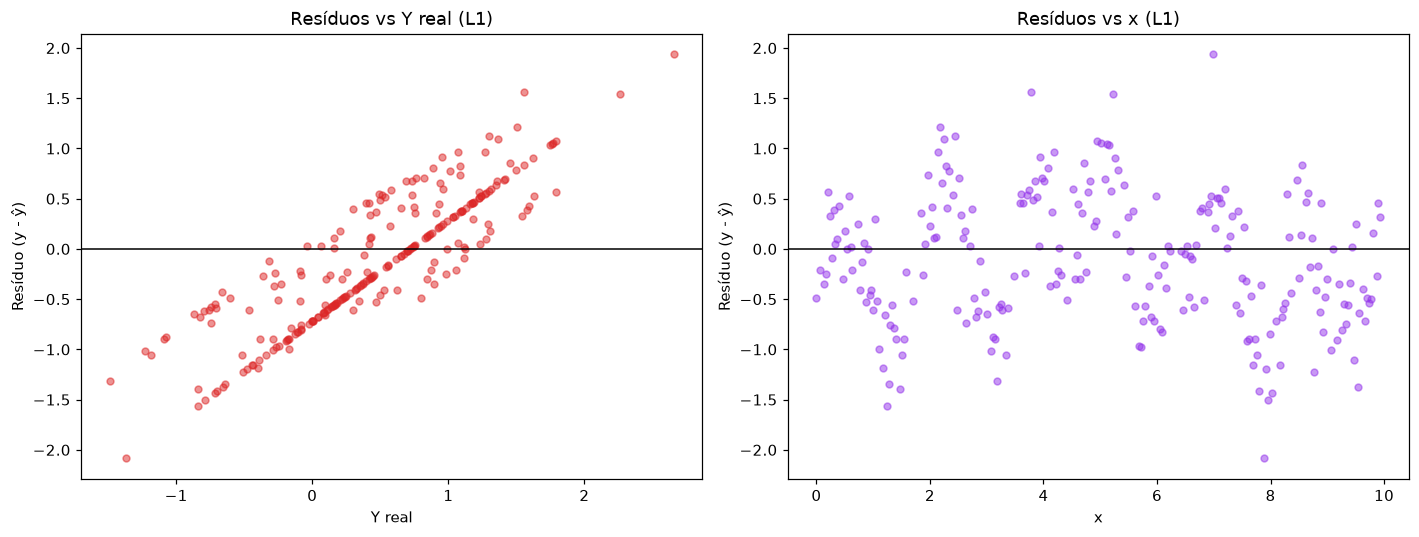

In [37]:
residuos = r_melhor["valores_reais"] - r_melhor["previsoes"]

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
eixos[0].scatter(r_melhor["valores_reais"], residuos, alpha=0.5, s=20, color="#dc2626")
eixos[0].axhline(0, color="black", linewidth=1)
eixos[0].set_xlabel("Y real"); eixos[0].set_ylabel("Resíduo (y - ŷ)")
eixos[0].set_title(f"Resíduos vs Y real ({melhor_modelo_teste})")

eixos[1].scatter(x_teste_original, residuos, alpha=0.5, s=20, color="#9333ea")
eixos[1].axhline(0, color="black", linewidth=1)
eixos[1].set_xlabel("x"); eixos[1].set_ylabel("Resíduo (y - ŷ)")
eixos[1].set_title(f"Resíduos vs x ({melhor_modelo_teste})")

plt.tight_layout()
plt.savefig("figuras/fig4_residuos.png", dpi=130)
plt.show()

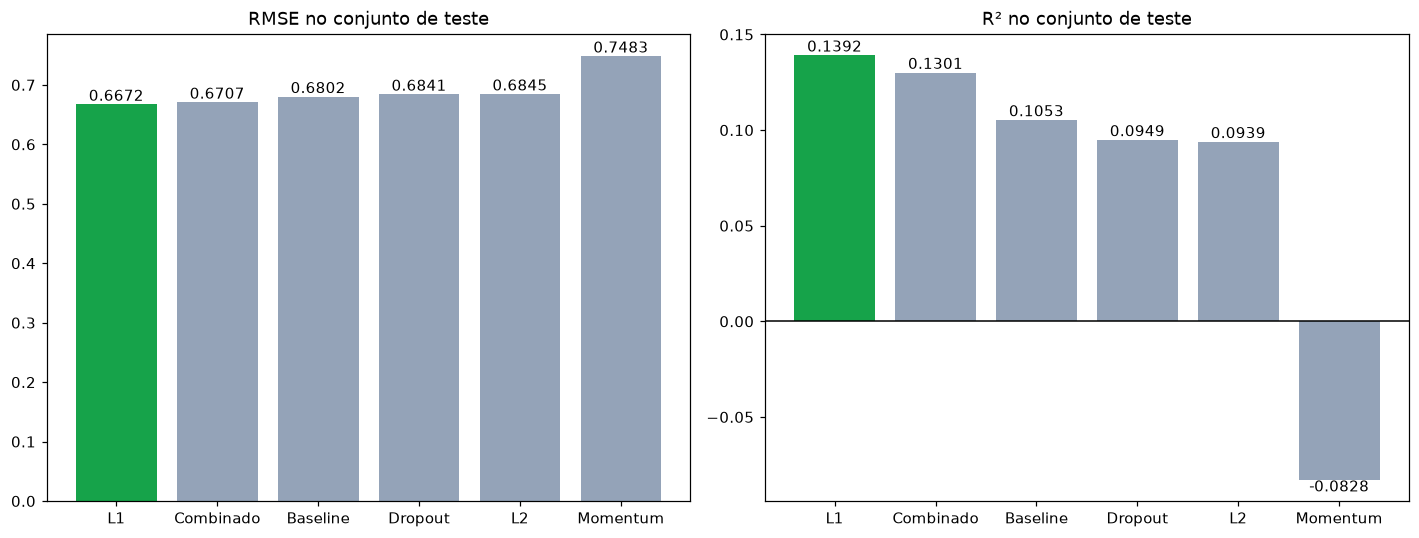

In [38]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

cores_rmse = ["#16a34a" if m == tabela_teste.iloc[0]["Modelo"] else "#94a3b8" for m in tabela_teste["Modelo"]]
barras_rmse = eixos[0].bar(tabela_teste["Modelo"], tabela_teste["RMSE"], color=cores_rmse)
eixos[0].bar_label(barras_rmse, fmt="%.4f")
eixos[0].set_title("RMSE no conjunto de teste")

tabela_r2 = tabela_teste.sort_values("R2", ascending=False)
cores_r2 = ["#16a34a" if m == tabela_r2.iloc[0]["Modelo"] else "#94a3b8" for m in tabela_r2["Modelo"]]
barras_r2 = eixos[1].bar(tabela_r2["Modelo"], tabela_r2["R2"], color=cores_r2)
eixos[1].bar_label(barras_r2, fmt="%.4f")
eixos[1].axhline(0, color="black", linewidth=1)
eixos[1].set_title("R² no conjunto de teste")

plt.tight_layout()
plt.savefig("figuras/fig5_rmse_r2.png", dpi=130)
plt.show()

## Conclusão

Ver discussão crítica completa em `relatorio.md`. Resumo dos resultados
principais desta execução:

In [40]:
melhor_validacao = tabela_validacao.iloc[0]
melhor_teste = tabela_teste.iloc[0]
melhor_r2 = tabela_teste.loc[tabela_teste["R2"].idxmax()]

print("RESUMO DOS RESULTADOS\n")
print("Melhor modelo na validação:", melhor_validacao["Modelo"],
      "| MSE val.:", f"{melhor_validacao['MSE de validação']:.6f}")
print("Menor RMSE no teste:", melhor_teste["Modelo"],
      "| RMSE:", f"{melhor_teste['RMSE']:.6f}", "| MAE:", f"{melhor_teste['MAE']:.6f}")
print("Maior R² no teste:", melhor_r2["Modelo"], "| R²:", f"{melhor_r2['R2']:.6f}")

RESUMO DOS RESULTADOS

Melhor modelo na validação: L1 | MSE val.: 0.860780
Menor RMSE no teste: L1 | RMSE: 0.667187 | MAE: 0.549974
Maior R² no teste: L1 | R²: 0.139154
